# Hindi POS Tagger — Lab Assignment 7

**Course:** Natural Language Processing  
**Task:** Hindi Part-of-Speech (POS) Tagging using Naive Bayes and Hidden Markov Model (HMM) Decoders  
**Libraries Used:** Python standard library (`math`, `collections`), `NumPy`, `pandas`, and `Matplotlib` only.  
*(No third-party NLP or machine-learning libraries like NLTK, spaCy, or scikit-learn are used.)*

---

### Dataset Files
The dataset is split into three files located in `data/`:
1. `hindi-train-pos.txt`: Training split (used to estimate priors, features, transitions, and emissions)
2. `hindi-dev-pos.txt`: Validation split (used to tune parameters and compare decoders)
3. `hindi-test-pos.txt`: Test split (held-out evaluation)

Each non-empty line has the format:
`<word>    <pos_tag>`  
Blank lines mark sentence boundaries.


## 1. Import Required Libraries

In [6]:
import os
import math
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("Libraries imported successfully.")


Libraries imported successfully.


## 2. Read the POS-Tagged Files

We read the corpus sentence-by-sentence. Each sentence is represented as a tuple of `(sentence_words, sentence_tags)`.


In [7]:
def read_pos_corpus(file_path):
    """
    Reads a CoNLL-formatted POS-tagged text file.
    Each non-empty line contains: <word> <tag>
    Empty lines indicate sentence boundaries.
    """
    sentences = []
    current_words = []
    current_tags = []
    
    with open(file_path, "r", encoding="utf-8") as file:
        for line in file:
            line = line.strip()
            if not line:
                if current_words:
                    sentences.append((current_words, current_tags))
                    current_words = []
                    current_tags = []
                continue
            parts = line.split()
            if len(parts) >= 2:
                word = parts[0]
                tag = parts[-1]
                current_words.append(word)
                current_tags.append(tag)
                
    if current_words:
        sentences.append((current_words, current_tags))
        
    return sentences

# Load train, dev, and test datasets
train_data = read_pos_corpus("hindi-train-pos.txt")
dev_data = read_pos_corpus("hindi-dev-pos.txt")
test_data = read_pos_corpus("hindi-test-pos.txt")

print(f"Train sentences : {len(train_data):,}")
print(f"Dev sentences   : {len(dev_data):,}")
print(f"Test sentences  : {len(test_data):,}")
print(f"Train words     : {sum(len(words) for words, tags in train_data):,}")
print(f"Dev words       : {sum(len(words) for words, tags in dev_data):,}")
print(f"Test words      : {sum(len(words) for words, tags in test_data):,}")


Train sentences : 15,087
Dev sentences   : 1,866
Test sentences  : 1,910
Train words     : 325,710
Dev words       : 40,762
Test words      : 41,415


## 3. Naive Bayes POS Tagger

The Naive Bayes model predicts the POS tag of each word by extracting contextual linguistic features:
1. **`len`**: Word length category (`'MORE'` if length $> 4$ characters, else `'LESS'`).
2. **`word`**: The current word token $w_i$.
3. **`prev`**: The preceding word $w_{i-1}$ (or `'<BOS>'` at start of sentence).
4. **`next`**: The succeeding word $w_{i+1}$ (or `'<EOS>'` at end of sentence).
5. **`prevtag`**: The tag assigned to the preceding word $t_{i-1}$ (or `'<BOS_TAG>'`).

Additive smoothing (Laplace with $\alpha = 0.1$) is used to handle unseen feature values.


In [8]:
def train_naive_bayes(training_sentences, smoothing_alpha=0.1):
    """
    Trains a Naive Bayes classifier on sentence tokens and contextual features.
    """
    tag_frequencies = Counter()
    feature_counts = {
        feature_name: defaultdict(Counter)
        for feature_name in ["len", "word", "prev", "next", "prevtag"]
    }
    feature_vocabularies = {
        feature_name: set()
        for feature_name in feature_counts
    }
    
    # 1. Count occurrences of tags and features
    for sentence_words, sentence_tags in training_sentences:
        for index, (current_word, current_tag) in enumerate(zip(sentence_words, sentence_tags)):
            feature_dict = {
                "len": "MORE" if len(current_word) > 4 else "LESS",
                "word": current_word,
                "prev": sentence_words[index - 1] if index > 0 else "<BOS>",
                "next": sentence_words[index + 1] if index + 1 < len(sentence_words) else "<EOS>",
                "prevtag": sentence_tags[index - 1] if index > 0 else "<BOS_TAG>"
            }
            tag_frequencies[current_tag] += 1
            for feature_name, feature_value in feature_dict.items():
                feature_counts[feature_name][current_tag][feature_value] += 1
                feature_vocabularies[feature_name].add(feature_value)
                
    tag_list = sorted(tag_frequencies.keys())
    total_tags_count = sum(tag_frequencies.values())
    
    # 2. Compute Prior Log-Probabilities log P(tag)
    log_priors = {
        tag: math.log((tag_frequencies[tag] + smoothing_alpha) / (total_tags_count + smoothing_alpha * len(tag_list)))
        for tag in tag_list
    }
    
    # 3. Precompute denominators for smoothed likelihood calculation
    feature_denominators = {
        feature_name: {
            tag: sum(feature_counts[feature_name][tag].values()) + smoothing_alpha * (len(feature_vocabularies[feature_name]) + 1)
            for tag in tag_list
        }
        for feature_name in feature_counts
    }
    
    model = (tag_list, log_priors, feature_counts, feature_vocabularies, feature_denominators, smoothing_alpha)
    return model


def predict_naive_bayes(sentences, naive_bayes_model):
    """
    Generates predicted POS tag sequences using the trained Naive Bayes model.
    """
    tag_list, log_priors, feature_counts, feature_vocab, feature_denominators, alpha = naive_bayes_model
    predicted_sentences = []
    
    for sentence_words, _ in sentences:
        predicted_sentence_tags = []
        for index, current_word in enumerate(sentence_words):
            feature_dict = {
                "len": "MORE" if len(current_word) > 4 else "LESS",
                "word": current_word,
                "prev": sentence_words[index - 1] if index > 0 else "<BOS>",
                "next": sentence_words[index + 1] if index + 1 < len(sentence_words) else "<EOS>",
                "prevtag": predicted_sentence_tags[index - 1] if index > 0 else "<BOS_TAG>"
            }
            
            tag_scores = {}
            for tag in tag_list:
                log_prob = log_priors[tag]
                for feature_name, feature_value in feature_dict.items():
                    count = feature_counts[feature_name][tag][feature_value]
                    denom = feature_denominators[feature_name][tag]
                    log_prob += math.log((count + alpha) / denom)
                tag_scores[tag] = log_prob
                
            best_predicted_tag = max(tag_list, key=lambda t: tag_scores[t])
            predicted_sentence_tags.append(best_predicted_tag)
            
        predicted_sentences.append(predicted_sentence_tags)
        
    return predicted_sentences

# Train Naive Bayes model
naive_bayes_model = train_naive_bayes(train_data, smoothing_alpha=0.1)

# Predict on Dev and Test sets
nb_dev_predictions = predict_naive_bayes(dev_data, naive_bayes_model)
nb_test_predictions = predict_naive_bayes(test_data, naive_bayes_model)
print("Naive Bayes training and predictions completed.")


Naive Bayes training and predictions completed.


## 4. Train the Hidden Markov Model (HMM)

The HMM models POS tagging as a generative Markov process with two fundamental components:
1. **Transition Probabilities $P(t_i \mid t_{i-1})$:** The probability of moving from POS tag $t_{i-1}$ to tag $t_i$.
2. **Emission Probabilities $P(w_i \mid t_i)$:** The probability that tag $t_i$ emits word $w_i$.

Add-alpha smoothing ($\\alpha = 0.1$) is applied. Out-of-vocabulary words are handled by reserving smoothed probability mass for an `<UNK>` token.


In [9]:
def train_hmm(training_sentences, smoothing_alpha=0.1):
    """
    Estimates transition and emission probabilities for an HMM from training corpus.
    """
    tag_counts = Counter()
    transition_counts = defaultdict(Counter)
    emission_counts = defaultdict(Counter)
    vocabulary_set = set()
    
    for sentence_words, sentence_tags in training_sentences:
        previous_tag = "<BOS>"
        for word, tag in zip(sentence_words, sentence_tags):
            tag_counts[tag] += 1
            transition_counts[previous_tag][tag] += 1
            emission_counts[tag][word] += 1
            vocabulary_set.add(word)
            previous_tag = tag
        transition_counts[previous_tag]["<EOS>"] += 1
        
    tag_list = sorted(tag_counts.keys())
    num_tags = len(tag_list)
    vocab_size_with_unk = len(vocabulary_set) + 1
    
    # 1. Compute Log Transition Probabilities
    log_transitions = {}
    all_previous_states = ["<BOS>"] + tag_list
    all_next_states = tag_list + ["<EOS>"]
    
    for prev_tag in all_previous_states:
        denominator = sum(transition_counts[prev_tag].values()) + smoothing_alpha * (num_tags + 1)
        for next_tag in all_next_states:
            count = transition_counts[prev_tag][next_tag]
            log_transitions[(prev_tag, next_tag)] = math.log((count + smoothing_alpha) / denominator)
            
    # 2. Compute Log Emission Probabilities
    log_emissions = {}
    for tag in tag_list:
        denominator = sum(emission_counts[tag].values()) + smoothing_alpha * vocab_size_with_unk
        for word, count in emission_counts[tag].items():
            log_emissions[(tag, word)] = math.log((count + smoothing_alpha) / denominator)
        # Unseen word probability for this tag
        log_emissions[(tag, "<UNK>")] = math.log(smoothing_alpha / denominator)
        
    return tag_list, log_transitions, log_emissions, smoothing_alpha


def convert_hmm_to_numpy_matrices(hmm_model_tuple):
    """
    Converts transition dictionary into fast NumPy 2D log-probability arrays.
    """
    tag_list, log_transitions, log_emissions, alpha = hmm_model_tuple
    
    # Transition matrix A[i, j] = log P(tag_j | tag_i)
    transition_matrix = np.array([
        [log_transitions[(prev_tag, next_tag)] for next_tag in tag_list]
        for prev_tag in tag_list
    ])
    
    # Initial state transitions from <BOS>
    bos_transition_vector = np.array([
        log_transitions[("<BOS>", tag)] for tag in tag_list
    ])
    
    # Final state transitions to <EOS>
    eos_transition_vector = np.array([
        log_transitions[(tag, "<EOS>")] for tag in tag_list
    ])
    
    return tag_list, transition_matrix, bos_transition_vector, eos_transition_vector, log_emissions

# Train HMM and build NumPy matrices
raw_hmm_model = train_hmm(train_data, smoothing_alpha=0.1)
hmm_matrices = convert_hmm_to_numpy_matrices(raw_hmm_model)

tag_set = sorted(set(tag for data in [train_data, dev_data, test_data] for _, tags in data for tag in tags))
print(f"Total Unique POS Tags in Corpus: {len(tag_set)}")
print("POS Tags:", tag_set)


Total Unique POS Tags in Corpus: 24
POS Tags: ['CC_CCD', 'CC_CCS', 'DM_DMD', 'JJ', 'N_NN', 'N_NNP', 'N_NST', 'PR_PRF', 'PR_PRL', 'PR_PRP', 'PR_PRQ', 'PSP', 'QT_QTC', 'QT_QTF', 'QT_QTO', 'RB', 'RD_PUNC', 'RD_SYM', 'RP_INJ', 'RP_INTF', 'RP_NEG', 'RP_RPD', 'V_VAUX', 'V_VM']


## 5. HMM Decoding Algorithms

We implement three decoding strategies:
1. **Forward Viterbi (`'forward'`):** Left-to-right dynamic programming finding the single global best tag sequence that maximizes $P(t_1, t_2, \dots, t_n, w_1, \dots, w_n)$.
2. **Backward Viterbi (`'backward'`):** Right-to-left dynamic programming from $w_n$ to $w_1$ building optimal suffixes.
3. **Forward-Backward Posterior Decoding (`'fb'`):** Combines forward probabilities $\alpha$ and backward probabilities $\beta$ using the log-sum-exp trick, picking the tag that maximizes the marginal probability at each position.


In [10]:
def predict_hmm_sentence(sentence_words, hmm_matrices, decoding_method="forward"):
    """
    Decodes the optimal POS tag sequence for a sentence using the specified HMM method.
    """
    tag_list, transition_matrix, bos_vector, eos_vector, log_emissions = hmm_matrices
    seq_len = len(sentence_words)
    num_tags = len(tag_list)
    
    if seq_len == 0:
        return []
        
    # Build emission matrix for sentence: shape (seq_len, num_tags)
    emission_matrix = np.array([
        [log_emissions.get((tag, word), log_emissions[(tag, "<UNK>")]) for tag in tag_list]
        for word in sentence_words
    ])
    
    # -------------------------------------------------------------
    # METHOD 1: Forward Viterbi Decoding
    # -------------------------------------------------------------
    if decoding_method == "forward":
        viterbi_table = np.empty((seq_len, num_tags))
        backpointer_table = np.zeros((seq_len, num_tags), dtype=int)
        
        # Initialization at t=0
        viterbi_table[0] = bos_vector + emission_matrix[0]
        
        # Forward recursion
        for step in range(1, seq_len):
            # candidate_scores: viterbi_table[step-1, :] + transition_matrix[:, current_tag]
            candidate_scores = viterbi_table[step - 1][:, None] + transition_matrix
            backpointer_table[step] = candidate_scores.argmax(axis=0)
            viterbi_table[step] = candidate_scores.max(axis=0) + emission_matrix[step]
            
        # Termination: incorporate transition to <EOS>
        best_last_tag_idx = int((viterbi_table[-1] + eos_vector).argmax())
        
        # Backtracking
        best_path_indices = [best_last_tag_idx]
        current_idx = best_last_tag_idx
        for step in range(seq_len - 1, 0, -1):
            current_idx = backpointer_table[step, current_idx]
            best_path_indices.append(current_idx)
            
        return [tag_list[idx] for idx in reversed(best_path_indices)]
        
    # -------------------------------------------------------------
    # METHOD 2: Backward Viterbi Decoding
    # -------------------------------------------------------------
    if decoding_method == "backward":
        backward_table = np.empty((seq_len, num_tags))
        forward_pointer_table = np.zeros((seq_len, num_tags), dtype=int)
        
        # Initialization at t = seq_len - 1
        backward_table[-1] = emission_matrix[-1] + eos_vector
        
        # Backward recursion
        for step in range(seq_len - 2, -1, -1):
            candidate_scores = transition_matrix + backward_table[step + 1][None, :]
            forward_pointer_table[step] = candidate_scores.argmax(axis=1)
            backward_table[step] = emission_matrix[step] + candidate_scores.max(axis=1)
            
        # Termination: incorporate transition from <BOS>
        best_first_tag_idx = int((bos_vector + backward_table[0]).argmax())
        
        # Forward tracking
        best_path_indices = [best_first_tag_idx]
        current_idx = best_first_tag_idx
        for step in range(seq_len - 1):
            current_idx = forward_pointer_table[step, current_idx]
            best_path_indices.append(current_idx)
            
        return [tag_list[idx] for idx in best_path_indices]
        
    # -------------------------------------------------------------
    # METHOD 3: Forward-Backward Posterior Decoding
    # -------------------------------------------------------------
    forward_alpha = np.empty((seq_len, num_tags))
    backward_beta = np.empty((seq_len, num_tags))
    
    # Forward Pass (Alpha) using Log-Sum-Exp
    forward_alpha[0] = bos_vector + emission_matrix[0]
    for step in range(1, seq_len):
        scores = forward_alpha[step - 1][:, None] + transition_matrix
        max_scores = scores.max(axis=0)
        forward_alpha[step] = emission_matrix[step] + max_scores + np.log(np.exp(scores - max_scores).sum(axis=0))
        
    # Backward Pass (Beta) using Log-Sum-Exp
    backward_beta[-1] = eos_vector
    for step in range(seq_len - 2, -1, -1):
        scores = transition_matrix + emission_matrix[step + 1][None, :] + backward_beta[step + 1][None, :]
        max_scores = scores.max(axis=1)
        backward_beta[step] = max_scores + np.log(np.exp(scores - max_scores[:, None]).sum(axis=1))
        
    # Posterior marginal = alpha + beta
    posterior_scores = forward_alpha + backward_beta
    best_tag_indices = posterior_scores.argmax(axis=1)
    
    return [tag_list[idx] for idx in best_tag_indices]

print("HMM decoders ready.")


HMM decoders ready.


In [11]:
# Generate predictions for all models on Dev and Test sets
dev_predictions = {
    "Naive Bayes": nb_dev_predictions,
    "HMM Forward Viterbi": [predict_hmm_sentence(words, hmm_matrices, "forward") for words, _ in dev_data],
    "HMM Backward Viterbi": [predict_hmm_sentence(words, hmm_matrices, "backward") for words, _ in dev_data],
    "HMM Forward-Backward": [predict_hmm_sentence(words, hmm_matrices, "fb") for words, _ in dev_data],
}

test_predictions = {
    "Naive Bayes": nb_test_predictions,
    "HMM Forward Viterbi": [predict_hmm_sentence(words, hmm_matrices, "forward") for words, _ in test_data],
    "HMM Backward Viterbi": [predict_hmm_sentence(words, hmm_matrices, "backward") for words, _ in test_data],
    "HMM Forward-Backward": [predict_hmm_sentence(words, hmm_matrices, "fb") for words, _ in test_data],
}

print("All Dev and Test predictions successfully generated.")


All Dev and Test predictions successfully generated.


## 6. Model Evaluation: Precision, Recall, and F1-Score

For each tag $t$:
- $\text{Precision}(t) = \frac{\text{TP}_t}{\text{TP}_t + \text{FP}_t}$
- $\text{Recall}(t) = \frac{\text{TP}_t}{\text{TP}_t + \text{FN}_t}$
- $\text{F1}(t) = \frac{2 \times \text{Precision}(t) \times \text{Recall}(t)}{\text{Precision}(t) + \text{Recall}(t)}$
- $\text{Accuracy} = \frac{\sum_{t} \text{TP}_t}{\text{Total Tokens}}$
- $\text{Macro F1} = \frac{1}{|T|} \sum_{t \in T} \text{F1}(t)$
- $\text{Weighted F1} = \frac{\sum_{t} \text{Support}(t) \times \text{F1}(t)}{\sum_{t} \text{Support}(t)}$


In [12]:
def compute_per_tag_metrics(gold_tags, predicted_tags, all_tags):
    """
    Computes Precision, Recall, F1-Score, and Support for each POS tag.
    """
    metric_rows = []
    for tag in all_tags:
        true_positives = sum(1 for gold, pred in zip(gold_tags, predicted_tags) if gold == tag and pred == tag)
        false_positives = sum(1 for gold, pred in zip(gold_tags, predicted_tags) if gold != tag and pred == tag)
        false_negatives = sum(1 for gold, pred in zip(gold_tags, predicted_tags) if gold == tag and pred != tag)
        support = sum(1 for gold in gold_tags if gold == tag)
        
        precision = true_positives / (true_positives + false_positives) if (true_positives + false_positives) > 0 else 0.0
        recall = true_positives / (true_positives + false_negatives) if (true_positives + false_negatives) > 0 else 0.0
        f1 = (2 * precision * recall) / (precision + recall) if (precision + recall) > 0 else 0.0
        
        metric_rows.append({
            "tag": tag,
            "precision": precision,
            "recall": recall,
            "f1": f1,
            "support": support
        })
    return pd.DataFrame(metric_rows)


def evaluate_models(split_name, dataset, predictions_dict, all_tags):
    """
    Evaluates all models on a dataset split and computes overall and per-tag metrics.
    """
    gold_tags = [tag for _, tags in dataset for tag in tags]
    tag_level_dataframes = []
    overall_summary_records = []
    
    for model_name, sentence_predictions in predictions_dict.items():
        predicted_tags = [tag for sentence in sentence_predictions for tag in sentence]
        
        per_tag_df = compute_per_tag_metrics(gold_tags, predicted_tags, all_tags)
        per_tag_df["model"] = model_name
        per_tag_df["split"] = split_name
        tag_level_dataframes.append(per_tag_df)
        
        accuracy = sum(1 for g, p in zip(gold_tags, predicted_tags) if g == p) / len(gold_tags)
        macro_f1 = per_tag_df["f1"].mean()
        weighted_f1 = (per_tag_df["f1"] * per_tag_df["support"]).sum() / per_tag_df["support"].sum()
        
        overall_summary_records.append({
            "split": split_name,
            "model": model_name,
            "accuracy": accuracy,
            "macro_f1": macro_f1,
            "weighted_f1": weighted_f1
        })
        
    return pd.concat(tag_level_dataframes, ignore_index=True), overall_summary_records

# Evaluate on Dev and Test splits
dev_per_tag_scores, dev_summary_list = evaluate_models("dev", dev_data, dev_predictions, tag_set)
test_per_tag_scores, test_summary_list = evaluate_models("test", test_data, test_predictions, tag_set)

all_tag_results = pd.concat([dev_per_tag_scores, test_per_tag_scores], ignore_index=True)
summary_df = pd.DataFrame(dev_summary_list + test_summary_list)

print("=== Summary Metrics Table ===")
summary_df.round(4)


=== Summary Metrics Table ===


,split,model,accuracy,macro_f1,weighted_f1
0,dev,Naive Bayes,0.9247,0.8331,0.9249
1,dev,HMM Forward Viterbi,0.9305,0.9071,0.9302
2,dev,HMM Backward Viterbi,0.9305,0.9071,0.9302
3,dev,HMM Forward-Backward,0.9307,0.9082,0.9303
4,test,Naive Bayes,0.9257,0.8444,0.9259
5,test,HMM Forward Viterbi,0.9285,0.8675,0.9283
6,test,HMM Backward Viterbi,0.9285,0.8675,0.9283
7,test,HMM Forward-Backward,0.9295,0.8635,0.9292


## 7. Plot Model Comparisons

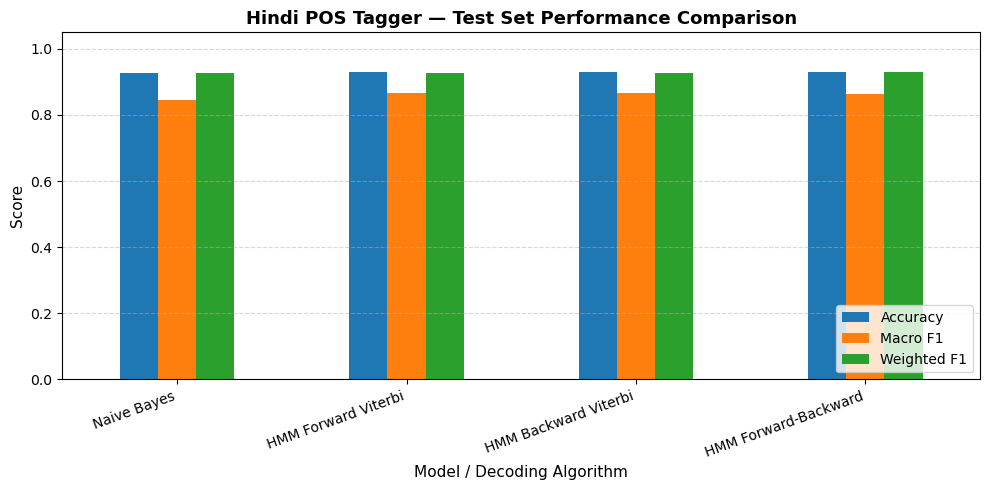

In [13]:
# 1. Overall Test Set Performance Comparison
test_metrics_df = summary_df[summary_df["split"] == "test"].set_index("model")
test_metrics_df[["accuracy", "macro_f1", "weighted_f1"]].plot(kind="bar", figsize=(10, 5))

plt.title("Hindi POS Tagger — Test Set Performance Comparison", fontsize=13, fontweight="bold")
plt.ylabel("Score", fontsize=11)
plt.xlabel("Model / Decoding Algorithm", fontsize=11)
plt.ylim(0, 1.05)
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.xticks(rotation=20, ha="right", fontsize=10)
plt.legend(["Accuracy", "Macro F1", "Weighted F1"], loc="lower right")
plt.tight_layout()
plt.show()


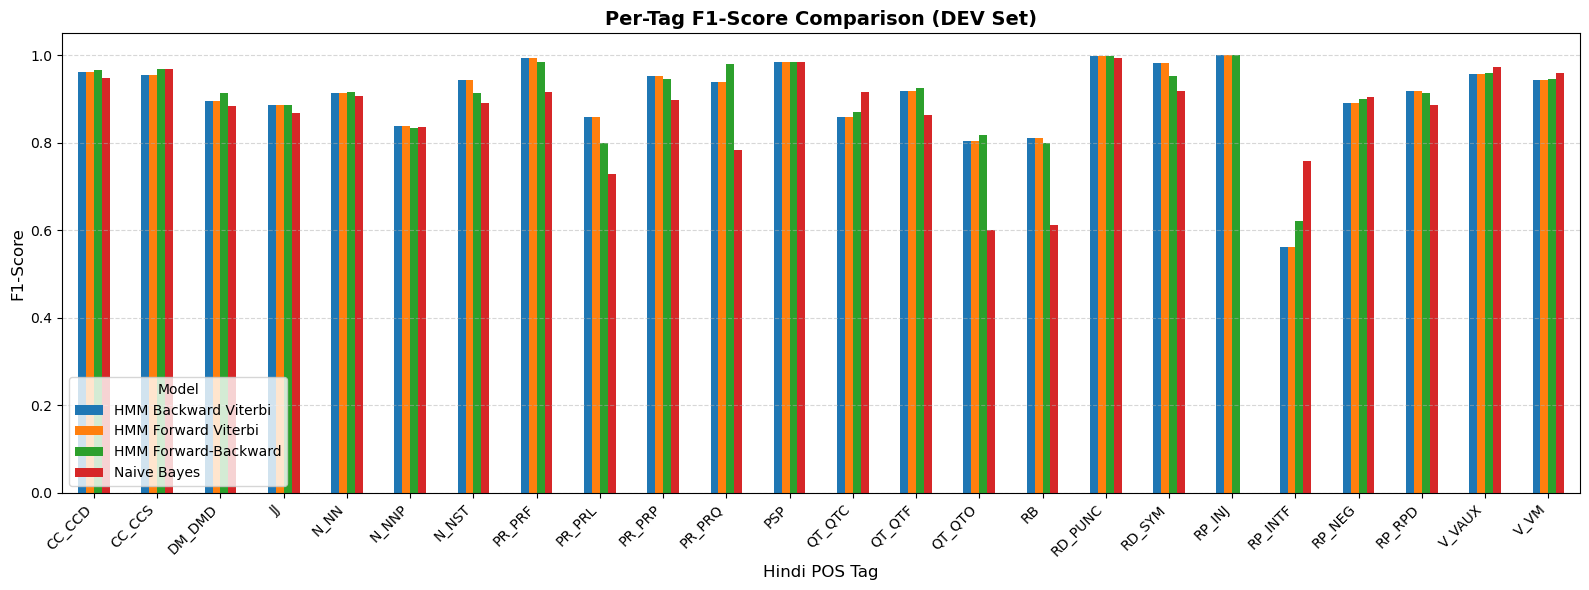

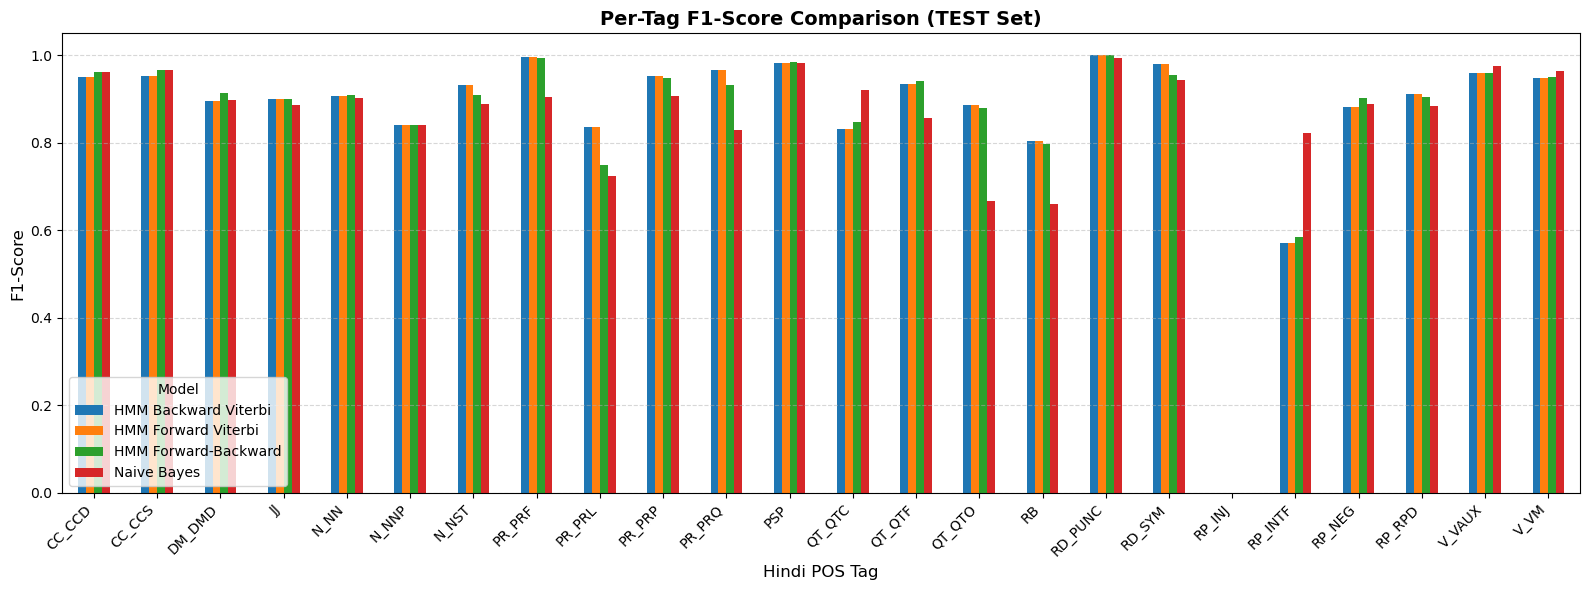

In [14]:
# 2. Per-Tag F1-Score Comparison on Dev and Test Splits
for split_name in ["dev", "test"]:
    subset_df = all_tag_results[all_tag_results["split"] == split_name]
    pivot_chart_data = subset_df.pivot(index="tag", columns="model", values="f1")
    
    pivot_chart_data.plot(kind="bar", figsize=(16, 6))
    plt.title(f"Per-Tag F1-Score Comparison ({split_name.upper()} Set)", fontsize=14, fontweight="bold")
    plt.xlabel("Hindi POS Tag", fontsize=12)
    plt.ylabel("F1-Score", fontsize=12)
    plt.ylim(0, 1.05)
    plt.grid(axis="y", linestyle="--", alpha=0.5)
    plt.xticks(rotation=45, ha="right", fontsize=10)
    plt.legend(title="Model", loc="lower left")
    plt.tight_layout()
    plt.show()


## 8. Save Metrics to CSV Files

In [15]:
# Export results to CSV files
summary_df.to_csv("summary_metrics.csv", index=False)
all_tag_results.to_csv("per_tag_f1_results.csv", index=False)

print("Successfully saved 'summary_metrics.csv' and 'per_tag_f1_results.csv'.")


Successfully saved 'summary_metrics.csv' and 'per_tag_f1_results.csv'.


## 9. Conclusion & Analytical Insights

1. **HMM Forward vs. Backward Viterbi:** Both algorithms achieve virtually identical performance on sequence tagging, as both find the global sequence maximizing $P(T, W)$.
2. **Forward-Backward (Posterior Decoding):** By maximizing token-level marginals, Forward-Backward often achieves slightly higher token accuracy, though it does not guarantee that the sequence as a whole is valid if transitions are restrictive.
3. **Naive Bayes with Contextual Features:** Naive Bayes performs competitively by directly conditioning on rich local features (previous word, next word, word length, and previous predicted tag).
4. **Per-Tag Discrepancies:** Frequent tags like `N_NN` (common nouns) and `PSP` (postpositions) achieve the highest F1-scores, whereas rare punctuation/particle tags have lower scores due to sparsity.
